# IMF Report → Insights Pipeline: Kyrgyz Republic (2025 Article IV)
**Report:** IMF Country Report No. 25/118, *Kyrgyz Republic: 2025 Article IV Consultation – Press Release; and Staff Report* (June 2025). Allocated country and period: Kyrgyzstan, 2024–2025. DOI: https://doi.org/10.5089/9798229013031.002

**Pipeline (this notebook runs top to bottom without manual steps):**

| Part | What it does |
|---|---|
| 0 | Setup: packages, settings, LLM provider and API key (Colab Secrets / environment variable), the report PDF |
| 1 | **Task 1**: parse and clean the PDF, detect sections, token-aware chunking, section summaries, executive summary, LLM-as-a-Judge |
| 2 | Retrieval index: local embeddings + FAISS (shared by Tasks 2 and 3) |
| 3 | **Task 2**: themes, strengths/vulnerabilities, JSON indicators with fallbacks, trends, judge audits |
| 4 | **Task 3**: RAG question answering with citations, closed-book comparison |
| 5 | **Extension**: Multi-Query RAG vs single-query RAG |
| 6 | **Task 4**: tidy data (`pd.melt`) and the 4-panel dashboard (300 dpi) |
| 7 | Run summary: API calls, cache use, latency |

**Design choices that apply everywhere**
- **Two different models:** a fast model extracts and summarises (`deepseek-flash` in the submitted run), a second, stronger model judges the output (`deepseek-v4-pro`). The provider can be switched to Gemini (OpenRouter or Google AI Studio) with one setting.
- **Disk caching:** every LLM answer is saved in `imf_cache/`, so re-running the notebook does not repeat API calls.
- **Temperature 0** for repeatable outputs; **retries with back-off** on rate limits and server errors (plus call spacing on free-tier keys).
- **Code checks every LLM output**: JSON schemas, evidence quotes found in the report, numbers found in their quotes, citations matched to retrieved chunks.
- All outputs are saved as `.json` in `outputs/`.

## 0. Setup
### 0.1 Install packages
Runs in Google Colab or locally (VS Code / Jupyter, Python 3.10+). After the first install in a fresh local environment, restart the kernel once.

In [1]:
# %pip installs into the kernel this notebook is running on (works in Colab, VS Code and Jupyter).
%pip install -q pypdf google-genai transformers sentence-transformers faiss-cpu pandas numpy matplotlib pydantic requests

### 0.2 Settings
Change these values only. Model names can be checked with the model list in 0.3.

In [2]:
import os, json, re, time
import pandas as pd

COUNTRY = "Kyrgyz Republic"                  # name used by the IMF (also printed as the running header)
REPORT_YEAR = 2025                          # Article IV consultation year, used in prompts and titles
REPORT_ID = "IMF Country Report No. 25/118 (2025 Article IV)"
CENTRAL_BANK = "NBKR"                       # National Bank of the Kyrgyz Republic (sets the policy rate)
PDF_URL = "https://meetings.imf.org/-/media/Files/Publications/CR/2025/English/1kgzea2025001-print-pdf.ashx"
PDF_PATH = "kyrgyz_republic_2025_article_iv.pdf"

# Which LLM service to use (only the key named here is needed):
#   "deepseek":   DeepSeek API (pay-as-you-go, very low cost),           key DEEPSEEK_API_KEY
#   "openrouter": Google Gemini models through OpenRouter ($5 top-up),   key OPENROUTER_API_KEY
#   "gemini":     Google AI Studio directly (free tier ~20 requests/day per model), key GEMINI_API_KEY
PROVIDER = "deepseek"

# A cheap, fast model does the high-volume summarising/extraction; a DIFFERENT, stronger model is the judge.
# If a name is not offered by the provider, cell 0.3 picks the closest available model and says so.
MODELS = {
    "deepseek":   ("deepseek-flash", "deepseek-v4-pro", "deepseek-v4-pro"),
    "openrouter": ("google/gemini-3.5-flash-lite", "google/gemini-3.5-flash", "google/gemini-3.8-flash"),
    "gemini":     ("gemini-3.5-flash-lite", "gemini-3.5-flash", "gemini-3.8-flash"),
}
EXTRACTOR_MODEL, JUDGE_MODEL, JUDGE_MODEL_2 = MODELS[PROVIDER]   # extractor | judge (Task 1) | judge (Tasks 2-3, extension)
V1_COMPARE_N = 99                           # baseline prompt (V1) on the first N sections (99 = all); use 4 on a free key to save quota

FREE_TIER = False    # paid tier (billing on): no daily cap, short pause between calls. Set True on a free key
                     # (about 20 requests/day per model): calls are then spaced out and a run may need two days.

TOKENIZER_NAME = "BAAI/bge-small-en-v1.5"   # same tokenizer as the embedding model used for RAG in Task 3
CHUNK_TOKENS, OVERLAP_TOKENS = 400, 50       # brief: 300-500 tokens with ~50-token overlap
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Cache of LLM answers. Colab deletes local files when the runtime restarts, so by default the cache is
# kept in Google Drive: re-runs then cost no API calls. Set USE_DRIVE_CACHE = False to keep it local only.
USE_DRIVE_CACHE = True
CACHE_DIR = "imf_cache"
if USE_DRIVE_CACHE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        CACHE_DIR = "/content/drive/MyDrive/IMF_Kyrgyzstan/imf_cache"   # separate folder: no answers/embeddings reused from another report
    except Exception as e:
        print("Drive not available, using a local cache:", e)
os.makedirs(CACHE_DIR, exist_ok=True)
print("LLM cache folder:", CACHE_DIR)

def save_json(obj, name):
    """Save any result to outputs/<name>.json (machine-readable output required by the brief)."""
    with open(os.path.join(OUT_DIR, name), "w") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)
    print("saved", os.path.join(OUT_DIR, name))

Mounted at /content/drive
LLM cache folder: /content/drive/MyDrive/IMF_Kyrgyzstan/imf_cache


### 0.3 LLM client
Three interchangeable services, chosen with `PROVIDER` in 0.2: **DeepSeek** (`DEEPSEEK_API_KEY`), Google Gemini through **OpenRouter** (`OPENROUTER_API_KEY`) or **Google AI Studio** directly (`GEMINI_API_KEY`). The key is read from **Colab Secrets** in Colab, or from an environment variable / a hidden prompt when run locally, so it never appears in the notebook. The cell lists the models the key can use and checks that the extractor and the judge are two different models.

In [3]:
import requests

def get_api_key(name: str) -> str:
    """Colab: read the key from Colab Secrets. Locally: read the environment variable `name`,
    or ask for it with a hidden prompt. The key is never written into the notebook."""
    try:
        from google.colab import userdata
        return userdata.get(name)
    except ImportError:
        pass
    key = os.environ.get(name)
    if not key:
        from getpass import getpass
        key = getpass(f"Paste your {name} (input hidden): ")
    return key

# OpenAI-compatible services: base URL and the secret that holds the key
OPENAI_COMPATIBLE = {"deepseek":   ("https://api.deepseek.com", "DEEPSEEK_API_KEY"),
                     "openrouter": ("https://openrouter.ai/api/v1", "OPENROUTER_API_KEY")}

if PROVIDER in OPENAI_COMPATIBLE:
    base_url, key_name = OPENAI_COMPATIBLE[PROVIDER]
    client = {"base_url": base_url, "api_key": get_api_key(key_name)}   # requests are sent with plain HTTP (see call_llm)
    r = requests.get(f"{base_url}/models", headers={"Authorization": f"Bearer {client['api_key']}"}, timeout=60)
    r.raise_for_status()                                     # a wrong key fails here, before any real work
    available = [m["id"] for m in r.json()["data"]]
else:
    from google import genai
    client = genai.Client(api_key=get_api_key("GEMINI_API_KEY"), http_options={"timeout": 120000})
    available = [m.name.replace("models/", "") for m in client.models.list()]

def pick(wanted: str, hints: tuple[str, ...]) -> str:
    """Use the requested model if offered; otherwise the first available model whose name contains a hint."""
    if wanted in available:
        return wanted
    for h in hints:
        match = sorted(m for m in available if h in m)
        if match:
            print(f"{wanted} is not offered - using {match[0]} instead"); return match[0]
    raise ValueError(f"{wanted} is not available. Models offered: {available}")

relevant = [m for m in available if PROVIDER != "openrouter" or m.startswith(("google/gemini", "deepseek/"))]
print("Models available:", sorted(relevant)[:40])
if PROVIDER == "deepseek":
    EXTRACTOR_MODEL = pick(EXTRACTOR_MODEL, ("flash", "chat"))
    JUDGE_MODEL = pick(JUDGE_MODEL, ("pro", "reasoner"))
else:
    EXTRACTOR_MODEL = pick(EXTRACTOR_MODEL, ("flash-lite",))
    JUDGE_MODEL = pick(JUDGE_MODEL, ("flash",))
JUDGE_MODEL_2 = JUDGE_MODEL_2 if JUDGE_MODEL_2 in available else JUDGE_MODEL
assert EXTRACTOR_MODEL != JUDGE_MODEL, "The judge must be a different model from the extractor"
print("Provider:", PROVIDER, "| Extractor:", EXTRACTOR_MODEL, "| Judge (Task 1):", JUDGE_MODEL, "| Judge (Tasks 2-3):", JUDGE_MODEL_2)

Models available: ['deepseek-flash', 'deepseek-v4-pro']
Provider: deepseek | Extractor: deepseek-flash | Judge (Task 1): deepseek-v4-pro | Judge (Tasks 2-3): deepseek-v4-pro


### 0.4 Get the report PDF
Downloaded from the IMF website. If the download fails, you are asked to upload the PDF instead.

In [4]:
import requests

def get_pdf(url: str, path: str) -> str:
    """Download the report once; fall back to a manual upload if the IMF site is unreachable."""
    if os.path.exists(path):
        return path
    try:
        r = requests.get(url, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
        if r.ok and r.content[:4] == b"%PDF":
            open(path, "wb").write(r.content)
            return path
        print("Download did not return a PDF (status", r.status_code, ")")
    except Exception as e:
        print("Download failed:", e)
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Download failed. Save the IMF report PDF as '{path}' next to this notebook and re-run.")
    print("Please upload the IMF report PDF:")
    uploaded = files.upload()
    name = next(iter(uploaded))
    os.rename(name, path)
    return path

get_pdf(PDF_URL, PDF_PATH)
print("PDF ready:", PDF_PATH, round(os.path.getsize(PDF_PATH) / 1e6, 2), "MB")

Download did not return a PDF (status 403 )
Please upload the IMF report PDF:


Saving 1kgzea2025001-print-pdf.pdf to 1kgzea2025001-print-pdf.pdf
PDF ready: kyrgyz_republic_2025_article_iv.pdf 2.86 MB


## 1. Task 1: PDF processing and summarisation
### 1.1 Parsing and cleaning
`pypdf` extracts text page by page. Cleaning removes the running headers and footers printed on every page (country name, *INTERNATIONAL MONETARY FUND* + page number, copyright), table-of-contents leader lines and stand-alone page numbers; it repairs words split across lines and re-joins wrapped lines into paragraphs.

Pages that are mostly numbers (tables, charts) are **flagged** with a digit-ratio test. They are left out of summarisation, where they add noise, but kept for indicator extraction in Task 2.

Sections are found with the **standard IMF Article IV headings** (Context, Policy Discussions, Staff Appraisal, Annexes, Debt Sustainability Analysis…). These are general IMF headings rather than text copied from this report, so the code would also work on another country's report.

In [5]:
# PDF loading, cleaning, sectioning (Task 1)
import re, unicodedata
from pypdf import PdfReader

# Running headers/footers that IMF prints on every page (country name, "INTERNATIONAL MONETARY FUND 16", copyright)
HEADER_PATTERNS = [
    r"^\s*\d*\s*INTERNATIONAL MONETARY FUND\s*\d*\s*$",
    r"^\s*©\s*\d{4}\s+International Monetary Fund\s*$",
    r"^\s*\d{1,3}\s*$",                       # stand-alone page numbers
]

# Standard IMF Article IV document structure. These are generic IMF headings (domain knowledge),
# not text copied from this report, so the same code works for other countries' reports.
SECTION_PATTERNS = [
    ("Press Release",                      r"^(FOR IMMEDIATE RELEASE|IMF Executive Board Concludes)"),
    ("Key Issues",                         r"^KEY ISSUES"),          # also "KEY ISSUES AND KEY POLICY RECOMMENDATIONS"
    ("Context",                            r"^CONTEXT$"),
    ("Recent Developments, Outlook and Risks", r"^(RECENT )?(ECONOMIC )?DEVELOPMENTS(,| AND|$)"),   # e.g. "ECONOMIC DEVELOPMENTS, OUTLOOK, AND RISKS"
    ("Policy Discussions",                 r"^POLICY DISCUSSIONS$"),
    ("Fund Relations",                     r"^(FUND RELATIONS|RELATIONS WITH THE FUND)$"),
    ("Staff Appraisal",                    r"^STAFF APPRAISAL$"),
    ("Annex",                              r"^Annex [IVX]+\.\s+\S"),
    ("Debt Sustainability Analysis",       r"DEBT SUSTAINABILITY ANALYSIS$"),   # may follow "STAFF REPORT FOR THE ... CONSULTATION—"
    ("Informational Annex",                r"INFORMATIONAL ANNEX$"),
    ("Staff Statement",                    r"^Statement by the IMF Staff Representative"),
    ("Executive Director Statement",       r"^Statement by .*Executive Director"),
]

def normalise(text: str) -> str:
    """Unify unicode characters that PDFs often use (non-breaking hyphens/spaces, curly quotes)."""
    text = unicodedata.normalize("NFKC", text)
    for a, b in {"‑": "-", "‐": "-", " ": " ", "‘": "'", "’": "'",
                 "“": '"', "”": '"', "": "•"}.items():
        text = text.replace(a, b)
    return text

def load_pdf_pages(path: str, country: str) -> list[dict]:
    """Read every page with pypdf and return raw text per page (1-based page numbers)."""
    reader = PdfReader(path)
    return [{"page": i + 1, "raw": normalise(p.extract_text() or "")} for i, p in enumerate(reader.pages)]

def is_table_page(text: str, threshold: float = 0.22) -> bool:
    """Pages that are mostly numbers (tables, charts) confuse summarisation, so we flag them.
    They are kept separately for numeric indicator extraction in Task 2."""
    chars = [c for c in text if not c.isspace()]
    if len(chars) < 200:
        return False
    digits = sum(c.isdigit() for c in chars)
    return digits / len(chars) > threshold

def clean_page(raw: str, country: str) -> str:
    """Remove running headers/footers, join wrapped lines into paragraphs and tidy spacing."""
    lines = [l.strip() for l in raw.splitlines()]
    keep = []
    for l in lines:
        if not l:
            continue
        if l.upper() == country.upper():                  # running header with the country name
            continue
        if any(re.match(p, l) for p in HEADER_PATTERNS):
            continue
        if re.search(r"(_{5,}|\.{5,}|…{2,})\s*\d+\s*$", l):   # table-of-contents lines with dot/underscore leaders
            continue
        keep.append(l)
    # Re-join lines into paragraphs: a new paragraph starts at a numbered paragraph ("12. "),
    # a bullet, or a known section heading; otherwise the line is a wrapped continuation.
    paras, cur, prev_heading = [], "", False
    for l in keep:
        heading = any(re.search(p, l) for _, p in SECTION_PATTERNS) and len(l) < 120
        new_para = (heading or prev_heading or re.match(r"^\d{1,2}\.\s+\S", l)
                    or l.startswith(("•", "-  ", "▪")))
        prev_heading = heading                             # a heading is always its own paragraph
        if new_para and cur:
            paras.append(cur); cur = l
        elif cur.endswith("-") and not cur.endswith(" -"):
            cur = cur + l                                  # word split across lines: "election-" + "related"
        else:
            cur = (cur + " " + l).strip()
    if cur:
        paras.append(cur)
    text = "\n".join(paras)
    text = re.sub(r"[ \t]{2,}", " ", text)
    return text.strip()

def detect_sections(pages: list[dict]) -> list[dict]:
    """Assign each page to a section by scanning for standard IMF headings.
    A page can start a new section part-way down; text before the heading stays in the previous section."""
    sections, current = [], {"name": "Front Matter", "pages": [], "text": ""}
    for p in pages:
        for para in p["clean"].split("\n"):
            hit = None
            for name, pat in SECTION_PATTERNS:
                if re.search(pat, para) and len(para) < 120:
                    hit = para if name == "Annex" else name
                    break
            if hit:
                hit = re.sub(r"(?<=[a-z])\d+$", "", hit)   # drop footnote markers, e.g. "Matrix1"
            if hit and hit != current["name"]:
                if current["text"].strip():
                    sections.append(current)
                current = {"name": hit, "pages": [], "text": ""}
            if p["page"] not in current["pages"]:
                current["pages"].append(p["page"])
            current["text"] += para + "\n"
    if current["text"].strip():
        sections.append(current)
    # Merge repeated names (e.g. the press release heading appears twice) into one section
    merged = {}
    for s in sections:
        m = merged.setdefault(s["name"], {"name": s["name"], "pages": [], "text": ""})
        m["pages"] = sorted(set(m["pages"] + s["pages"])); m["text"] += s["text"]
    return list(merged.values())

def clean_table_page(raw: str, country: str) -> str:
    """For table pages keep the line structure (one table row per line) and drop only headers/footers."""
    lines = [l.strip() for l in raw.splitlines() if l.strip()]
    keep = [l for l in lines if l.upper() != country.upper() and not any(re.match(p, l) for p in HEADER_PATTERNS)]
    return "\n".join(keep)


In [6]:
pages = load_pdf_pages(PDF_PATH, COUNTRY)
for p in pages:
    p["is_table"] = is_table_page(p["raw"])
    p["clean"] = clean_page(p["raw"], COUNTRY)

narrative_pages = [p for p in pages if not p["is_table"]]
table_pages = [p for p in pages if p["is_table"]]
sections = detect_sections(narrative_pages)

raw_words = sum(len(p["raw"].split()) for p in pages)
clean_words = sum(len(p["clean"].split()) for p in pages)
print(f"{len(pages)} pages | {len(table_pages)} table/chart pages flagged | words raw {raw_words:,} -> clean {clean_words:,}")
sec_table = pd.DataFrame([{"section": s["name"], "pages": f'{s["pages"][0]}-{s["pages"][-1]}',
                           "words": len(s["text"].split())} for s in sections])
save_json([{k: s[k] for k in ("name", "pages", "text")} for s in sections], "sections.json")
sec_table

83 pages | 15 table/chart pages flagged | words raw 31,668 -> clean 30,701
saved outputs/sections.json


,section,pages,words
0,Front Matter,1-2,224
1,Press Release,2-5,884
2,Key Issues,5-7,458
3,Context,8-8,273
4,"Recent Developments, Outlook and Risks",8-10,815
5,Policy Discussions,10-18,3846
6,Staff Appraisal,18-33,1216
7,Annex I. Risk Assessment Matrix,34-37,1189
8,Annex II. External Sector Assessment,38-41,1600
9,Annex III. Estimating Debt Limits,42-45,1584


### 1.2 Token-aware chunking
Chunks are counted in **tokens of the embedding model's tokenizer** (`BAAI/bge-small-en-v1.5`, max 512 tokens), so every chunk fits the RAG embedder in Task 3 without being cut off. Chunks hold whole sentences (no sentence is split in half) up to **400 tokens**, and each new chunk repeats about **50 tokens** of the previous chunk's last sentences so that context at the boundaries is not lost.

In [7]:
# Token-aware chunking (Task 1)
import re

def split_sentences(text: str) -> list[str]:
    """Split into sentences, protecting common abbreviations used in IMF reports."""
    protected = re.sub(r"\b(e\.g|i\.e|U\.S|No|Fig|vs|approx)\.", lambda m: m.group(0).replace(".", "§"), text)
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9(\"•])|\n+", protected)
    return [p.replace("§", ".").strip() for p in parts if p.strip()]

def chunk_text(text: str, count_tokens, max_tokens: int = 400, overlap_tokens: int = 50,
               meta: dict | None = None) -> list[dict]:
    """Pack whole sentences into chunks of at most `max_tokens`, carrying ~`overlap_tokens`
    of the previous chunk's final sentences into the next chunk so context is not lost at boundaries."""
    sents = split_sentences(text)
    chunks, cur, cur_tok = [], [], 0
    def flush():
        if cur:
            chunks.append({**(meta or {}), "text": " ".join(cur), "n_tokens": cur_tok})
    for s in sents:
        t = count_tokens(s)
        if t > max_tokens:                                   # very long "sentence" (e.g. a table row run-on): hard-split by words
            words = s.split(); step = max(1, int(len(words) * max_tokens / t))
            pieces = [" ".join(words[i:i + step]) for i in range(0, len(words), step)]
        else:
            pieces = [s]
        for piece in pieces:
            pt = count_tokens(piece)
            if cur and cur_tok + pt > max_tokens:
                flush()
                carry, carry_tok = [], 0                     # sentence-level overlap
                for prev in reversed(cur):
                    if carry_tok >= overlap_tokens:
                        break
                    carry.insert(0, prev); carry_tok += count_tokens(prev)
                if carry_tok > max_tokens // 2 or carry_tok + pt > max_tokens:   # overlap must never push a chunk over the limit
                    carry, carry_tok = [], 0
                cur, cur_tok = carry, carry_tok
            cur.append(piece); cur_tok += pt
    flush()
    return chunks


In [8]:
try:
    from transformers import AutoTokenizer
    from huggingface_hub.utils import logging as hf_logging
    hf_logging.set_verbosity_error()                     # hide the harmless "unauthenticated requests" notice
    _tok = AutoTokenizer.from_pretrained(TOKENIZER_NAME)
    _tok.model_max_length = 10**9                        # only COUNTING here (long rows are split later), so no 512 warning
    count_tokens = lambda s: len(_tok.encode(s, add_special_tokens=False))
    print("Token counts use", TOKENIZER_NAME)
except Exception as e:                        # offline fallback: about 1.33 tokens per English word
    print("Tokenizer unavailable, using word-based estimate:", e)
    count_tokens = lambda s: int(len(s.split()) * 1.33) + 1

chunks = []
for s in sections:
    chunks += chunk_text(s["text"], count_tokens, CHUNK_TOKENS, OVERLAP_TOKENS,
                         {"section": s["name"], "pages": f'{s["pages"][0]}-{s["pages"][-1]}'})
for i, c in enumerate(chunks):
    c["chunk_id"] = i
save_json(chunks, "chunks.json")
sizes = pd.Series([c["n_tokens"] for c in chunks])
print(f"{len(chunks)} chunks | tokens min {sizes.min()}, median {int(sizes.median())}, max {sizes.max()}")

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Token counts use BAAI/bge-small-en-v1.5
saved outputs/chunks.json
104 chunks | tokens min 66, median 375, max 413


### 1.3 LLM client with caching
`call_llm` is the only function that talks to the LLM (DeepSeek, Gemini through OpenRouter, or Google AI Studio). It caches every answer on disk (key = hash of model, prompt, system instruction and schema), spaces live calls when `FREE_TIER = True`, retries on rate-limit or server errors, checks JSON answers against a **Pydantic schema**, and logs latency and token use for later analysis.

In [9]:
# LLM client with disk caching, retries and rate limiting
import os, json, time, hashlib, requests
from pydantic import BaseModel

CACHE_DIR = globals().get("CACHE_DIR", "imf_cache")   # set in 0.2; every LLM answer is saved here, so re-runs cost no API calls
RATE_LIMIT_SECONDS = 13.0 if globals().get("FREE_TIER", True) else 0.5   # free tier: about 5 requests/minute per model

class QuotaExhausted(Exception):
    """Raised when the daily request limit is reached, so cells can stop politely and keep finished work."""
_last_call = [0.0]
CALL_LOG = []                      # one row per call: model, prompt id, latency, cached?, tokens

def _cache_path(payload: dict) -> str:
    key = hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:24]
    return os.path.join(CACHE_DIR, f"{key}.json")

def _strip_fences(text: str) -> str:
    """Some routes wrap JSON in ```json ... ``` fences; remove them before schema validation."""
    t = text.strip()
    if t.startswith("```"):
        t = t.split("\n", 1)[1] if "\n" in t else t[3:]
        t = t.rsplit("```", 1)[0]
    return t.strip()

def _send(client, prompt, model, system, schema, temperature):
    """One request to the chosen provider. Returns (text, token usage). JSON answers are schema-constrained."""
    if PROVIDER in ("openrouter", "deepseek"):                # OpenAI-compatible chat completions API
        if schema and PROVIDER == "deepseek":
            # DeepSeek's JSON mode guarantees valid JSON but not the structure, so the schema goes into the
            # instructions; the reply is still validated against the Pydantic schema afterwards.
            system = ((system or "") + "\n\nReturn ONLY a JSON object (no prose, no markdown) that matches this "
                      "JSON schema exactly:\n" + json.dumps(schema.model_json_schema())).strip()
        messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
        body = {"model": model, "messages": messages, "temperature": temperature}
        if PROVIDER == "openrouter":
            body["usage"] = {"include": True}                  # ask OpenRouter to report the cost of each call
            if schema:
                body["response_format"] = {"type": "json_schema",
                                           "json_schema": {"name": schema.__name__, "strict": False,
                                                           "schema": schema.model_json_schema()}}
        elif schema:
            body["response_format"] = {"type": "json_object"}
        r = requests.post(f"{client['base_url']}/chat/completions", timeout=300, json=body,
                          headers={"Authorization": f"Bearer {client['api_key']}"})
        if r.status_code != 200:
            raise RuntimeError(f"{r.status_code} {r.text[:300]}")
        data = r.json()
        if "error" in data:
            raise RuntimeError(f"{data['error'].get('code')} {data['error'].get('message')}")
        u = data.get("usage") or {}
        return (data["choices"][0]["message"].get("content") or "",
                {"prompt_tokens": u.get("prompt_tokens"), "output_tokens": u.get("completion_tokens"), "cost_usd": u.get("cost")})
    from google.genai import types
    config = types.GenerateContentConfig(
        temperature=temperature, system_instruction=system,
        response_mime_type="application/json" if schema else "text/plain",
        response_schema=schema if schema else None)
    resp = client.models.generate_content(model=model, contents=prompt, config=config)
    usage = getattr(resp, "usage_metadata", None)
    return (resp.text or "", {"prompt_tokens": getattr(usage, "prompt_token_count", None),
                              "output_tokens": getattr(usage, "candidates_token_count", None)})

def call_llm(client, prompt: str, model: str, system: str | None = None,
             schema: type[BaseModel] | None = None, temperature: float = 0.0,
             tag: str = "", max_retries: int = 5):
    """Send one prompt to the LLM and return text (or a parsed dict when `schema` is given).
    Identical requests are answered from the local cache instead of the API."""
    os.makedirs(CACHE_DIR, exist_ok=True)
    payload = {"model": model, "prompt": prompt, "system": system, "temperature": temperature,
               "schema": schema.model_json_schema() if schema else None}
    path = _cache_path(payload)
    if os.path.exists(path):
        with open(path) as f:
            rec = json.load(f)
        CALL_LOG.append({**rec["log"], "cached": True, "tag": tag})
        return rec["output"]

    for attempt in range(max_retries):
        wait = RATE_LIMIT_SECONDS - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        try:
            t0 = time.time()
            text, usage = _send(client, prompt, model, system, schema, temperature)
            latency = time.time() - t0
            _last_call[0] = time.time()
            output = text
            schema_ok = None
            if schema:
                try:
                    output = schema.model_validate_json(_strip_fences(text)).model_dump()   # strict schema check
                    schema_ok = True
                except Exception:
                    output = {"_raw": text, "_parse_error": True}
                    schema_ok = False
            log = {"model": model, "latency_s": round(latency, 2), "schema_ok": schema_ok, **usage}
            with open(path, "w") as f:
                json.dump({"payload": payload, "output": output, "log": log}, f, indent=1)
            CALL_LOG.append({**log, "cached": False, "tag": tag})
            return output
        except Exception as e:                       # rate limits / temporary server errors: back off and retry
            msg = str(e)
            if "PerDay" in msg or "per day" in msg.lower() or msg.startswith("402") or "Insufficient Balance" in msg:
                raise QuotaExhausted(f"limit reached for {model} (daily quota, or account credit used up); finished calls are cached") from None
            if attempt < max_retries - 1 and any(k in msg for k in ("429", "RESOURCE_EXHAUSTED", "500", "502", "503", "UNAVAILABLE", "DEADLINE", "timed out")):
                time.sleep(min(60, 8 * 2 ** attempt)); continue
            raise


### 1.4 Prompts, summarisation loop and judge
- **V1 (baseline):** a plain one-line prompt.
- **V2 (optimised):** a system instruction (analyst role, use only the given text, keep numbers exactly) plus explicit rules (under 100 words, one paragraph, lead with the main finding).
- **Long sections** (over 6,000 tokens) use a **map-reduce loop**: key facts are extracted from blocks of chunks, then combined into one summary.
- A **shortening loop** re-prompts if a summary breaks the 100-word limit.
- The **judge** is a different model with its own strict system instruction. It returns scores (1–5) for consistency, completeness and factual alignment, plus lists of unsupported claims and missing points, in a fixed JSON schema.

In [10]:
# Task 1: summaries and the LLM-as-a-Judge
from pydantic import BaseModel, Field

# Prompts. V1 is a plain baseline; V2 is the optimised version (role, rules, grounding, length limit).
SECTION_PROMPT_V1 = "Summarise this section of an IMF report.\n\n{text}"

SECTION_SYSTEM_V2 = (
    "You are an IMF macro-financial analyst writing for a policy audience. "
    "Use ONLY information stated in the text you are given; never add outside knowledge or guesses. "
    "Keep every number exactly as written, with its unit and year. "
    "If the text gives no figure for something, do not invent one."
)
SECTION_PROMPT_V2 = (
    "Summarise the section '{name}' of the {country} IMF Article IV report below.\n"
    "Rules:\n"
    "1. Fewer than 100 words, one paragraph of plain prose (no bullets, no headings).\n"
    "2. Lead with the main finding; then the key figures, risks and IMF recommendations.\n"
    "3. Only facts present in the text.\n\n"
    "SECTION TEXT:\n{text}"
)
MAP_PROMPT = (
    "From this extract of the section '{name}' of the {country} IMF report, list the key facts as short "
    "bullets: main findings, figures (with units and years), risks and recommendations. "
    "Only facts present in the extract.\n\nEXTRACT:\n{text}"
)
SHORTEN_PROMPT = (
    "This summary has {n} words but must have fewer than 100. Rewrite it in under 90 words, keeping the most "
    "important figures and findings, and adding nothing new.\n\nSUMMARY:\n{summary}"
)
EXEC_SYSTEM = SECTION_SYSTEM_V2
EXEC_PROMPT = (
    "Using ONLY the section summaries and source extracts below from the {country} IMF Article IV report, "
    "write an executive summary of the report's main FINANCIAL STABILITY findings and RISK assessments.\n"
    "Rules: 6 to 8 bullet points; each bullet under 35 words; start each bullet with '- '; include the "
    "specific figure where one is given; end each bullet with the section it comes from in square brackets, "
    "e.g. [Staff Appraisal].\n\n{context}"
)

# Judge (a second, different model). Strict JSON so scores can be analysed and plotted.
class JudgeScore(BaseModel):
    consistency: int = Field(ge=1, le=5, description="Summary does not contradict the source")
    completeness: int = Field(ge=1, le=5, description="Main points of the source are covered")
    factual_alignment: int = Field(ge=1, le=5, description="Every number and claim is supported by the source")
    unsupported_claims: list[str] = Field(description="Claims or numbers in the summary NOT found in the source")
    missing_key_points: list[str] = Field(description="Important source points the summary leaves out")
    rationale: str = Field(description="Two sentences explaining the scores")

JUDGE_SYSTEM = (
    "You are a strict, impartial auditor of AI-generated summaries of IMF reports. You compare a SUMMARY "
    "with its SOURCE text only. You do not reward fluent writing; you check facts. Any number in the summary "
    "that does not appear in the source is an unsupported claim."
)
JUDGE_PROMPT = (
    "Score the SUMMARY against the SOURCE on a 1-5 scale for each criterion "
    "(5 = no problems, 3 = some problems, 1 = mostly wrong or missing):\n"
    "- consistency: no contradictions with the source\n"
    "- completeness: covers the source's main points\n"
    "- factual_alignment: every number and claim is supported by the source\n"
    "List every unsupported claim and every important missing point.\n\n"
    "SOURCE:\n{source}\n\nSUMMARY:\n{summary}"
)

def word_count(text: str) -> int:
    return len(text.split())

def summarise_section(client, model, section, country, count_tokens, chunks,
                      version="v2", direct_limit_tokens=12000):
    """Summarise one section in <100 words.
    Sections longer than `direct_limit_tokens` use a map-reduce loop: key facts are extracted from each group of chunks (map),
    then combined into one summary (reduce). A shortening loop enforces the word limit."""
    name, text = section["name"], section["text"]
    if version == "v1":                                   # baseline: one plain prompt, no rules
        return {"summary": call_llm(client, SECTION_PROMPT_V1.format(text=text), model, tag=f"sum_v1:{name}"),
                "map_steps": 0, "shorten_steps": 0}
    map_steps = 0
    if count_tokens(text) > direct_limit_tokens:
        sec_chunks = [c["text"] for c in chunks if c["section"] == name]
        groups, cur, cur_tok = [], [], 0                 # group chunks into ~3,000-token blocks to save calls
        for c in sec_chunks:
            t = count_tokens(c)
            if cur and cur_tok + t > 3000:
                groups.append(" ".join(cur)); cur, cur_tok = [], 0
            cur.append(c); cur_tok += t
        if cur: groups.append(" ".join(cur))
        facts = [call_llm(client, MAP_PROMPT.format(name=name, country=country, text=g), model,
                          system=SECTION_SYSTEM_V2, tag=f"map:{name}") for g in groups]
        map_steps = len(groups)
        text = "\n".join(facts)
    summary = call_llm(client, SECTION_PROMPT_V2.format(name=name, country=country, text=text), model,
                       system=SECTION_SYSTEM_V2, tag=f"sum_v2:{name}")
    shorten_steps = 0
    while word_count(summary) >= 100 and shorten_steps < 2:
        summary = call_llm(client, SHORTEN_PROMPT.format(n=word_count(summary), summary=summary), model,
                           system=SECTION_SYSTEM_V2, tag=f"shorten:{name}")
        shorten_steps += 1
    return {"summary": summary.strip(), "map_steps": map_steps, "shorten_steps": shorten_steps}

def judge(client, judge_model, source, summary, tag=""):
    """Second model audits a summary against its source text and returns structured scores."""
    return call_llm(client, JUDGE_PROMPT.format(source=source, summary=summary), judge_model,
                    system=JUDGE_SYSTEM, schema=JudgeScore, tag=f"judge:{tag}")


### 1.5 Section summaries: baseline (V1) vs optimised (V2), each audited by the judge
V2 and the plain V1 baseline are both run on every section (`V1_COMPARE_N = 99`; set it to 4 on a free key to save quota), so the comparison covers the whole report. All summaries are written first, then judged, so a judge quota limit never blocks summarisation. If a daily limit is reached the cell stops politely; re-running later continues from the cache.

In [11]:
to_summarise = [s for s in sections if s["name"] != "Front Matter" and len(s["text"].split()) >= 150]
section_results = []
try:                                                    # phase A: summaries (extractor model)
    for i, s in enumerate(to_summarise):
        row = {"section": s["name"], "source_words": len(s["text"].split())}
        for version in (("v1", "v2") if i < V1_COMPARE_N else ("v2",)):
            out = summarise_section(client, EXTRACTOR_MODEL, s, COUNTRY, count_tokens, chunks, version=version)
            row[version] = {**out, "words": word_count(out["summary"])}
        section_results.append(row)
except QuotaExhausted as e:
    print("STOPPED (summaries):", e)

by_name = {s["name"]: s for s in sections}
try:                                                    # phase B: judge every summary against its own section text
    for row in section_results:
        for version in ("v1", "v2"):
            if version in row and "judge" not in row[version]:
                row[version]["judge"] = judge(client, JUDGE_MODEL, by_name[row["section"]]["text"],
                                              row[version]["summary"], tag=f"{version}:{row['section']}")
except QuotaExhausted as e:
    print("STOPPED (judging):", e)

for row in section_results:
    v1 = f'{row["v1"]["words"]:>4}' if "v1" in row else "   -"
    judged = "judged" if "judge" in row["v2"] else "not judged yet"
    print(f'{row["section"][:45]:<47} v1 {v1} words | v2 {row["v2"]["words"]:>3} words | {judged}')
print(f"\n{len(section_results)} of {len(to_summarise)} sections summarised.")
save_json(section_results, "section_summaries.json")

Press Release                                   v1  316 words | v2  95 words | judged
Key Issues                                      v1  232 words | v2  99 words | judged
Context                                         v1  183 words | v2  95 words | judged
Recent Developments, Outlook and Risks          v1  361 words | v2  95 words | judged
Policy Discussions                              v1  476 words | v2  96 words | judged
Staff Appraisal                                 v1  327 words | v2  93 words | judged
Annex I. Risk Assessment Matrix                 v1  546 words | v2  80 words | judged
Annex II. External Sector Assessment            v1  357 words | v2  93 words | judged
Annex III. Estimating Debt Limits               v1  405 words | v2  81 words | judged
Annex IV. Implementation of Key Recommendatio   v1  346 words | v2  90 words | judged
Annex V. Data Issues                            v1  186 words | v2  55 words | judged
Fund Relations                                  v1  33

In [12]:
def judge_row(r, v):
    j = r.get(v, {}).get("judge")
    ok = isinstance(j, dict) and not j.get("_parse_error")
    return {"section": r["section"], "prompt": v.upper(), "words": r[v]["words"],
            "under_100_words": r[v]["words"] < 100,
            "consistency": j["consistency"] if ok else None,
            "completeness": j["completeness"] if ok else None,
            "factual_alignment": j["factual_alignment"] if ok else None,
            "unsupported_claims": len(j["unsupported_claims"]) if ok else None}

summary_scores = pd.DataFrame([judge_row(r, v) for r in section_results for v in ("v1", "v2") if v in r])
# Fair comparison: only sections that have BOTH versions
paired = summary_scores[summary_scores["section"].isin([r["section"] for r in section_results if "v1" in r])]
comparison = paired.groupby("prompt")[["words", "under_100_words", "consistency", "completeness",
                                       "factual_alignment", "unsupported_claims"]].mean().round(2)
save_json(summary_scores.to_dict(orient="records"), "summary_judge_scores.json")
print("All V2 summaries - mean judge scores:")
print(summary_scores[summary_scores.prompt == "V2"][["consistency", "completeness", "factual_alignment"]].mean().round(2).to_string())
comparison

saved outputs/summary_judge_scores.json
All V2 summaries - mean judge scores:
consistency          4.92
completeness         2.23
factual_alignment    4.77


,words,under_100_words,consistency,completeness,factual_alignment,unsupported_claims
prompt,,,,,,
V1,336.62,0.0,4.92,4.15,4.69,0.38
V2,88.15,1.0,4.92,2.23,4.77,0.23


Read each V2 summary next to its judge comments. **Check flagged unsupported claims against the PDF yourself**: the judge can be wrong too.

In [13]:
for r in section_results:
    j = r["v2"].get("judge")
    print(f'### {r["section"]}  ({r["v2"]["words"]} words, map steps {r["v2"]["map_steps"]}, shorten steps {r["v2"]["shorten_steps"]})')
    print(r["v2"]["summary"])
    if isinstance(j, dict) and not j.get("_parse_error"):
        print(f'Judge: C{j["consistency"]} / Comp{j["completeness"]} / F{j["factual_alignment"]} | unsupported: {j["unsupported_claims"]}')
    print()

### Press Release  (95 words, map steps 0, shorten steps 0)
The IMF Executive Board found strong Kyrgyz performance amid global uncertainty: robust growth, stabilizing inflation and declining public debt. The economy grew 9 percent annually since 2022, and public debt fell to 36.6 percent of GDP in 2024. Growth is projected to moderate to 6.8 percent in 2025 and about 5¼ percent over the medium term, with public debt under 42 percent of GDP. Risks include heightened uncertainty and moderating re-export trade. The IMF recommends rebuilding policy buffers, enhancing fiscal sustainability, safeguarding monetary policy independence and advancing structural reforms to boost productivity and inclusive growth.
Judge: C5 / Comp3 / F5 | unsupported: []

### Key Issues  (99 words, map steps 0, shorten steps 0)
Inflation has declined to mid-single digits, but demand pressures require vigilance; growth is expected to moderate to around 51⁄4 percent over the medium term as re-export trade normalize

### 1.6 Executive summary
Built from the V2 section summaries plus the original text of the three parts where the IMF states its overall view (**Key Issues, Staff Appraisal, Press Release**). The judge then checks it against the **full narrative text of the report**, not just the summaries, so any claim that was distorted along the way is caught.

In [14]:
by_name = {s["name"]: s for s in sections}
context = "SECTION SUMMARIES:\n" + "\n".join(f'[{r["section"]}] {r["v2"]["summary"]}' for r in section_results)
for key in ("Key Issues", "Staff Appraisal", "Press Release"):
    if key in by_name:
        context += f"\n\nSOURCE EXTRACT [{key}]:\n" + by_name[key]["text"]

full_text = "\n\n".join(f'[{s["name"]}]\n{s["text"]}' for s in sections)
try:
    exec_summary = call_llm(client, EXEC_PROMPT.format(country=COUNTRY, context=context), EXTRACTOR_MODEL,
                            system=EXEC_SYSTEM, tag="exec_summary").strip()
    exec_judge = judge(client, JUDGE_MODEL, full_text, exec_summary, tag="exec_summary")
except QuotaExhausted as e:
    print("STOPPED:", e); exec_summary, exec_judge = "", {}

bullets = [b for b in exec_summary.splitlines() if b.strip().startswith("-")]
save_json({"executive_summary": exec_summary, "n_bullets": len(bullets), "judge": exec_judge}, "executive_summary.json")
print(exec_summary, "\n")
print("Judge:", {k: exec_judge.get(k) for k in ("consistency", "completeness", "factual_alignment")})
print("Unsupported claims:", exec_judge.get("unsupported_claims"))

saved outputs/executive_summary.json
- Financial sector risks are contained, but continued vigilance is needed amid rapid credit growth and elevated NPLs; NBKR should stand ready to provide targeted bank support if needed. [Key Issues]
- Banks remain well capitalized and liquid; regulatory capital to risk-weighted assets was 22.0 and liquidity ratio 73.1 in Dec-24, while NPLs/total loans remained high at 10.8. [Staff Appraisal]
- Profitability remained strong, but NPLs remain high; loan-loss provisioning/nonperforming loans was 45.9 in Dec-24, and FX exposure stayed at a 10-year low. [Staff Appraisal]
- The Risk Assessment Matrix finds mostly medium-impact risks, with high-likelihood trade and investment shocks, sovereign debt distress, deepening geoeconomic fragmentation and cyberthreats all High/Medium. [Annex I. Risk Assessment Matrix]
- Regional conflicts, commodity price volatility, systemic instability, climate change and social discontent are Medium/Medium, while global growth a

## 2. Retrieval index (Task 3 component, built first because Task 2 also uses it)
Every narrative chunk **and** every table page is embedded locally with `BAAI/bge-small-en-v1.5` (sentence-transformers) and stored in an exact **FAISS `IndexFlatL2`**. Vectors are L2-normalised, so L2 distance ranks passages the same way as cosine similarity. Embeddings are cached to disk. No API calls are used here, and retrieved text is never typed into prompts by hand.

In [15]:
#  Retrieval index: local dense embeddings + FAISS (Task 3, also used by Task 2)
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "BAAI/bge-small-en-v1.5"      # small, strong English retrieval model; 512-token input limit
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "   # recommended for BGE queries

embedder = SentenceTransformer(EMBED_MODEL)

def embed(texts: list[str]) -> np.ndarray:
    """Dense, L2-normalised embeddings (so L2 distance ranks the same way as cosine similarity)."""
    return embedder.encode(texts, normalize_embeddings=True, batch_size=32,
                           show_progress_bar=False).astype("float32")

def build_index(docs: list[dict], cache_file: str):
    """Embed every chunk once and cache the vectors on disk; build an exact FAISS IndexFlatL2."""
    if os.path.exists(cache_file):
        vecs = np.load(cache_file)
        if len(vecs) != len(docs):              # chunks changed -> re-embed
            vecs = embed([d["text"] for d in docs]); np.save(cache_file, vecs)
    else:
        vecs = embed([d["text"] for d in docs]); np.save(cache_file, vecs)
    index = faiss.IndexFlatL2(vecs.shape[1])
    index.add(vecs)
    return index

def retrieve(query: str, k: int = 5) -> list[dict]:
    """Return the k chunks closest to the query, with their L2 distance (smaller = more similar)."""
    q = embed([QUERY_PREFIX + query])
    dist, idx = rag_index.search(q, k)
    return [{**rag_docs[i], "distance": round(float(d), 4), "rank": r + 1}
            for r, (d, i) in enumerate(zip(dist[0], idx[0])) if i >= 0]

def format_context(hits: list[dict]) -> str:
    """Context block for prompts, each passage labelled so answers can cite it."""
    return "\n\n".join(f'[chunk {h["chunk_id"]} | {h["section"]} | pages {h["pages"]}]\n{h["text"]}' for h in hits)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [16]:
table_docs = []
for p in table_pages:
    t = clean_table_page(p["raw"], COUNTRY)
    for c in chunk_text(t.replace("\n", " \n "), count_tokens, CHUNK_TOKENS, 0, {"section": f'Table page {p["page"]}', "pages": str(p["page"])}):
        table_docs.append(c)
rag_docs = [dict(c) for c in chunks] + table_docs
for i, d in enumerate(rag_docs):
    d["chunk_id"] = i
rag_index = build_index(rag_docs, os.path.join(CACHE_DIR, "embeddings_bge_small.npy"))
print(f"Index: {rag_index.ntotal} vectors ({len(chunks)} narrative chunks + {len(table_docs)} table chunks)")
for h in retrieve("non-performing loans ratio", 3):
    print(f'  rank {h["rank"]} | dist {h["distance"]} | {h["section"]} | pages {h["pages"]}')

Index: 165 vectors (104 narrative chunks + 61 table chunks)
  rank 1 | dist 0.6112 | Table page 79 | pages 79
  rank 2 | dist 0.6294 | Policy Discussions | pages 10-18
  rank 3 | dist 0.6513 | Debt Sustainability Analysis | pages 63-83


## 3. Task 2: thematic extraction, indicators and structured output
### 3.1 Thematic distribution across the 7 financial-stability themes
A transparent **keyword lexicon** (regular expressions) is counted per section, not per chunk, so overlapping chunk text is never double-counted. Counts are also expressed **per 10,000 words** so themes can be compared fairly. No API calls: the counting is deterministic and reproducible.

In [17]:
# Task 2: themes, risk insights, indicators, trends
import re
from pydantic import BaseModel, Field

# 2.1 Thematic distribution: transparent keyword lexicon, counted in code (no API calls needed)
THEMES = {
    "Inflation & Prices":          r"\binflation\w*|\bconsumer prices?\b|\bCPI\b|\bprice pressures?\b|\bfood prices?\b|\bdeflator\b|\bdisinflation\b",
    "Interest Rates & Credit":     r"\binterest rates?\b|\bpolicy rate\b|\bcredit\b|\blending\b|\bloans?\b|\bmonetary polic\w*|\byields?\b|\bmicrofinance\b",
    "Housing & Real Estate":       r"\bhousing\b|\breal estate\b|\bpropert(y|ies)\b|\bmortgages?\b|\bland (titles?|registry)\b|\bconstruction\b",
    "Banking Capital & Liquidity": r"\bbanks?\b|\bbanking\b|\bcapital (adequacy|requirements?|ratios?|buffers?)\b|\bliquidity\b|\bnon-?performing\b|\bNPLs?\b|\bprovision\w*|\bNBKR\b|\bdeposits?\b|\bbank supervision\b",
    "Sovereign Debt":              r"\bdebt\b|\bborrowing\b|\bconcessional\b|\bamortization\w*|\bdebt service\b|\barrears\b|\bDSA\b|\bdebt distress\b|\bgross financing needs?\b",
    "Labor Market Dynamics":       r"\bemployment\b|\bunemployment\b|\bjobs?\b|\blabou?r\b|\bwages?\b|\bworkforce\b|\binformal (sector|economy)\b|\bmigrants?\b|\bmigration\b",
    "Systemic Financial Risk":     r"\bsystemic\b|\bfinancial stability\b|\bcontagion\b|\bsovereign-bank nexus\b|\bmacroprudential\b|\bstress tests?\b|\bspillovers?\b|\bfinancial sector risks?\b|\bdollari[sz]ation\b|\bsecondary sanctions\b",
}

def theme_counts(sections: list[dict]) -> dict:
    """Count keyword matches per theme in each section's text (sections, not chunks, so overlapping
    chunk text is never counted twice). Returns totals, density per 10,000 words and a per-section matrix."""
    counts = {t: 0 for t in THEMES}
    per_section = {}
    for s in sections:
        row = {t: len(re.findall(p, s["text"], flags=re.I)) for t, p in THEMES.items()}
        per_section[s["name"]] = row
        for t, n in row.items():
            counts[t] += n
    total_words = sum(len(s["text"].split()) for s in sections)
    density = {t: round(n / total_words * 10000, 2) for t, n in counts.items()}
    return {"counts": counts, "per_10k_words": density, "per_section": per_section, "total_words": total_words}

# 2.2 Qualitative risk insights (one LLM call, every item must quote its evidence)
class Insight(BaseModel):
    item: str = Field(description="Short label, e.g. 'Strong remittance inflows'")
    explanation: str = Field(description="One sentence")
    evidence: str = Field(description="An exact quote (8-30 words) copied from the context that supports the item")
    section: str = Field(description="Section the quote comes from")

class RiskInsights(BaseModel):
    strengths: list[Insight] = Field(description="5 to 7 growth drivers or strengths")
    vulnerabilities: list[Insight] = Field(description="5 to 7 systemic vulnerabilities or challenges")

INSIGHT_SYSTEM = ("You are an IMF macro-financial analyst. Use ONLY the context provided. Every item must be "
                  "supported by an exact quote copied word for word from the context.")
INSIGHT_PROMPT = ("From the context below from the {country} IMF Article IV report, extract:\n"
                  "- strengths: 5 to 7 national macroeconomic growth drivers or strengths\n"
                  "- vulnerabilities: 5 to 7 systemic vulnerabilities or challenges\n"
                  "Each item needs a one-sentence explanation and an exact supporting quote (8-30 words) copied "
                  "from the context, with the section name.\n\nCONTEXT:\n{context}")

# 2.3 Core indicators: strict JSON with evidence; missing values get a null fallback with a reason
class IndicatorValue(BaseModel):
    value: float | None = Field(default=None, description="The number in percent, or null if the report does not give this exact measure")
    period: str | None = Field(default=None, description="Year or period the value refers to, e.g. '2026 (projection)'")
    evidence: str | None = Field(default=None, description="Exact quote from the context containing the number")
    note: str | None = Field(default=None, description="If null: why the value is missing, or which related measure exists instead")

class IndicatorExtraction(BaseModel):
    country_name: str
    gdp_growth_forecast_pct: IndicatorValue
    headline_inflation_rate_pct: IndicatorValue
    central_bank_policy_rate_pct: IndicatorValue
    non_performing_loan_ratio: IndicatorValue
    unemployment_rate_pct: IndicatorValue
    tier_1_capital_ratio: IndicatorValue

INDICATOR_QUERIES = {
    "gdp_growth_forecast_pct": "real GDP growth projection for next year",
    "headline_inflation_rate_pct": "headline consumer price inflation rate average",
    "central_bank_policy_rate_pct": "NBKR policy rate National Bank of the Kyrgyz Republic percent",
    "non_performing_loan_ratio": "non-performing loans ratio to total loans banks",
    "unemployment_rate_pct": "unemployment rate labour market",
    "tier_1_capital_ratio": "Tier 1 capital ratio bank capital adequacy risk-weighted assets",
}
INDICATOR_SYSTEM = ("You extract economic indicators from IMF reports into strict JSON. Use ONLY the context. "
                    "Never estimate, compute or use outside knowledge. A related but different measure is NOT a "
                    "substitute (e.g. total capital ratio is not Tier 1; a regional rate must be stated as such).")
INDICATOR_PROMPT = (
    "Extract these indicators for {country} from the context. All values are percentages.\n"
    "- gdp_growth_forecast_pct: real GDP growth forecast for the next year projected in the report\n"
    "- headline_inflation_rate_pct: latest headline (average consumer price) inflation\n"
    "- central_bank_policy_rate_pct: the policy rate of the central bank that sets {country}'s monetary policy\n"
    "- non_performing_loan_ratio: gross non-performing loans to total loans, latest year\n"
    "- unemployment_rate_pct: the unemployment rate\n"
    "- tier_1_capital_ratio: Tier 1 capital to risk-weighted assets, latest year\n"
    "For each: value, period, an exact evidence quote containing the number, and a note. If the exact measure "
    "is not in the context, set value to null and explain in the note what is missing or what related measure "
    "exists instead.\nTables: the extracted text may lose column headers; if a table title gives a year range "
    "(e.g. '2024-31') and a row has one value per year, map the values to the years in order.\n\nCONTEXT:\n{context}")

# 2.4 Trends over time (for longitudinal plots)
class Series(BaseModel):
    name: str
    unit: str
    years: list[int]
    values: list[float]
    first_projection_year: int | None = Field(default=None, description="First year that is a projection, if any")
    source: str = Field(description="Table or section the series comes from")

class Trends(BaseModel):
    series: list[Series]

TREND_PROMPT = (
    "From the IMF report tables below for {country}, extract these time series exactly as printed:\n"
    "1. Real GDP growth (GDP at constant prices), percent, all years in the table\n"
    "2. Consumer price inflation (average), percent, all years\n"
    "3. Domestic credit to the private sector, all years (state its unit)\n"
    "4. Non-performing loans (gross) to total loans, percent, all years\n"
    "5. Gross loan annualized growth rate, percent, all years\n"
    "6. Central bank policy rate, percent, all years that show a number (skip years printed as '...')\n"
    "7. Tier 1 capital to risk-weighted assets, percent, all years\n"
    "Tables may lose their column headers in extraction: if a table title gives a year range (e.g. '2024-31' or "
    "'2018-23') and a row has one value per year, map the values to the years in order. Mark the first projection "
    "year when the table distinguishes estimates/projections. Copy numbers exactly; never fill gaps.\n\nTABLES:\n{context}")

def grounded_context(hits: list[dict]) -> str:
    """Context for extraction prompts. Narrative hits are passed as retrieved chunks, but any hit from a
    table page is replaced by the WHOLE cleaned table page: chunking splits a table, so the row that is
    needed (e.g. 'Policy Rate') can sit in a different chunk from the one the query happened to retrieve."""
    narrative = [h for h in hits if not h["section"].startswith("Table")]
    page_nums = sorted({int(h["pages"]) for h in hits if h["section"].startswith("Table")})
    by_page = {p["page"]: p for p in table_pages}
    parts = [format_context(narrative)] if narrative else []
    parts += [f"[Table page {n}]\n{clean_table_page(by_page[n]['raw'], COUNTRY)}" for n in page_nums if n in by_page]
    return "\n\n".join(parts)

# 2.5 Judge audits of the structured outputs
class FieldAudit(BaseModel):
    field: str
    verdict: str = Field(description="One of: correct, incorrect, unsupported, correct_fallback, wrong_fallback")
    comment: str

class StructuredAudit(BaseModel):
    audits: list[FieldAudit]
    overall_accuracy_score: int = Field(ge=1, le=5)
    summary: str

AUDIT_SYSTEM = ("You are a strict auditor of AI-extracted data from IMF reports. Check every field only against the "
                "SOURCE. A null value is 'correct_fallback' only if the source really lacks that exact measure.")
AUDIT_PROMPT = ("Audit each field of the EXTRACTED output against the SOURCE. For every field give a verdict "
                "(correct, incorrect, unsupported, correct_fallback, wrong_fallback) and a short comment, then an "
                "overall accuracy score from 1 to 5.\n\nSOURCE:\n{source}\n\nEXTRACTED:\n{extracted}")

# Code-level checks (no LLM): is each quote really in the report, and does it contain the number?
def _norm(s: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[^\w.%\- ]", " ", s or "")).strip().lower()

def quote_in_source(quote: str, source: str) -> bool:
    q = _norm(quote)
    return bool(q) and q in _norm(source)

def number_in_text(value, text: str) -> bool:
    if value is None or not text:
        return False
    found = [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", text.replace(",", ""))]
    return any(abs(f - float(value)) < 1e-6 for f in found)


In [18]:
themes = theme_counts(sections)
save_json(themes, "themes.json")
theme_table = pd.DataFrame({"mentions": themes["counts"], "per_10k_words": themes["per_10k_words"]}).sort_values("mentions", ascending=False)
theme_table

saved outputs/themes.json


,mentions,per_10k_words
Sovereign Debt,385,178.80
Banking Capital & Liquidity,209,97.06
Interest Rates & Credit,120,55.73
Labor Market Dynamics,62,28.79
Inflation & Prices,62,28.79
Systemic Financial Risk,24,11.15
Housing & Real Estate,18,8.36


### 3.2 Strengths and vulnerabilities (qualitative risk insights)
Context = passages retrieved for four risk/strength queries + the Key Issues and Staff Appraisal sections. Every item must quote its evidence; the code then **checks each quote really appears in the report**.

In [19]:
ctx_hits = {}
for q in ["growth drivers strengths and resilience of the economy", "main risks vulnerabilities and challenges",
          "downside risks to the outlook", "financial sector weaknesses banks",
          "remittances gold exports re-exports and dependence on Russia"]:
    for h in retrieve(q, 6):
        ctx_hits[h["chunk_id"]] = h
insight_context = format_context(list(ctx_hits.values()))
for key in ("Key Issues", "Staff Appraisal"):
    if key in by_name:
        insight_context += f"\n\n[{key}]\n" + by_name[key]["text"]

insights = None
try:
    insights = call_llm(client, INSIGHT_PROMPT.format(country=COUNTRY, context=insight_context), EXTRACTOR_MODEL,
                        system=INSIGHT_SYSTEM, schema=RiskInsights, tag="insights")
except QuotaExhausted as e:
    print("STOPPED:", e)
if insights and not insights.get("_parse_error"):
    for kind in ("strengths", "vulnerabilities"):
        for it in insights[kind]:
            it["quote_found_in_report"] = quote_in_source(it["evidence"], full_text)
        n = len(insights[kind]); found = sum(i["quote_found_in_report"] for i in insights[kind])
        print(f"{kind}: {n} items ({'OK' if 5 <= n <= 7 else 'outside 5-7'}), quotes verified in report: {found}/{n}")
        for it in insights[kind]:
            print(f'  - {it["item"]}  [{"quote found" if it["quote_found_in_report"] else "QUOTE NOT FOUND"}]')
    save_json(insights, "risk_insights.json")

strengths: 7 items (OK), quotes verified in report: 7/7
  - Robust broad-based growth  [quote found]
  - Moderated inflation  [quote found]
  - Fiscal space from lower public debt  [quote found]
  - Strong revenue and prudent fiscal stance  [quote found]
  - Well-capitalized and liquid banks  [quote found]
  - External trade and labor/capital inflows  [quote found]
  - Reserve accumulation  [quote found]
vulnerabilities: 7 items (OK), quotes verified in report: 7/7
  - Geopolitical outlook uncertainty  [quote found]
  - Sanctions on Russia  [quote found]
  - Re-export trade normalization  [quote found]
  - Elevated NPLs  [quote found]
  - Rapid credit growth  [quote found]
  - Persistent demand pressures  [quote found]
  - Limited export diversification  [quote found]
saved outputs/risk_insights.json


### 3.3 Core indicators as strict JSON, with fallbacks
For each indicator a retrieval query collects the relevant narrative passages, and any matching **table is passed as its whole page** (chunking splits tables, so a needed row can sit in a chunk the query did not retrieve; an earlier run missed the policy rate for exactly this reason). The model must return the value **with an exact evidence quote**; the code then checks (1) the quote is really in the report, (2) the number is really in the quote and (3) the number appears in the report at all (otherwise it is treated as a hallucination and set to `null`). Missing measures get a **`null` fallback with a reason**, never a guess. The output follows the target schema exactly.

In [20]:
ind_hits = {}
for field, q in INDICATOR_QUERIES.items():
    for h in retrieve(q, 4):
        ind_hits[h["chunk_id"]] = h
# Two table-oriented queries make sure the summary tables are always in the context
for q in ["Selected Economic Indicators table real GDP consumer prices policy rate",
          "Financial Soundness Indicators nonperforming loans Tier 1 capital to risk weighted assets"]:
    for h in retrieve(q, 4):
        if h["section"].startswith("Table"):
            ind_hits[h["chunk_id"]] = h
indicator_context = grounded_context(list(ind_hits.values()))   # table hits -> whole table pages

indicators_detail, indicators = None, None
try:
    indicators_detail = call_llm(client, INDICATOR_PROMPT.format(country=COUNTRY, context=indicator_context),
                                 EXTRACTOR_MODEL, system=INDICATOR_SYSTEM, schema=IndicatorExtraction, tag="indicators")
except QuotaExhausted as e:
    print("STOPPED:", e)

FIELDS = list(INDICATOR_QUERIES)
full_doc_text = full_text + "\n" + "\n".join(clean_table_page(p["raw"], COUNTRY) for p in table_pages)
if indicators_detail and not indicators_detail.get("_parse_error"):
    indicators = {"country_name": indicators_detail.get("country_name") or COUNTRY}
    checks, fallback_reasons = {}, {}
    for f in FIELDS:
        iv = indicators_detail.get(f) or {}
        val = iv.get("value")
        quote_ok = quote_in_source(iv.get("evidence") or "", full_doc_text)   # quote really in the report?
        num_ok = number_in_text(val, iv.get("evidence") or "")                 # number really in the quote?
        if val is not None and not number_in_text(val, full_doc_text):        # number appears nowhere -> likely invented
            fallback_reasons[f] = f"value {val} does not appear anywhere in the report; treated as hallucination and set to null"
            val = None
        elif val is None:
            fallback_reasons[f] = iv.get("note") or "not reported"
        indicators[f] = None if val is None else float(val)
        checks[f] = {"period": iv.get("period"), "evidence": iv.get("evidence"), "quote_found": quote_ok, "number_in_quote": num_ok}
    save_json(indicators, "indicators.json")                     # exact target schema
    save_json({"indicators": indicators, "checks": checks, "fallback_reasons": fallback_reasons,
               "model_output": indicators_detail}, "indicators_detailed.json")
    display(pd.DataFrame({"value": {f: indicators[f] for f in FIELDS},
                          "period": {f: checks[f]["period"] for f in FIELDS},
                          "quote_found": {f: checks[f]["quote_found"] for f in FIELDS},
                          "fallback_reason": {f: fallback_reasons.get(f, "") for f in FIELDS}}))

saved outputs/indicators.json
saved outputs/indicators_detailed.json


,value,period,quote_found,fallback_reason
gdp_growth_forecast_pct,6.8,2025 (projection),True,
headline_inflation_rate_pct,5.0,2024,True,
central_bank_policy_rate_pct,9.0,2024,True,
non_performing_loan_ratio,10.8,2024,True,
unemployment_rate_pct,4.1,2023,True,
tier_1_capital_ratio,17.4,2024,True,


### 3.4 Trends over time
One retrieval query per series finds the relevant **table pages** (searching deeper than usual, because narrative text often outranks tables), and the whole pages are given to the model. The code checks that each series has one value per year and that every number appears in the source. Projections are marked from the report year on (IMF tables show the previous year as an outturn or estimate).

In [21]:
trend_hits = {}
def retrieve_tables(query: str, n: int = 2, depth: int = 40) -> list[dict]:
    """Best n TABLE hits for a query: search deeper than usual, because narrative chunks often outrank the
    table that actually holds the series (this is how the FSI table was missed in an earlier run)."""
    return [h for h in retrieve(query, depth) if h["section"].startswith("Table")][:n]

for q in ["Selected Economic Indicators table real GDP growth", "consumer prices percent change average end of period",
          "credit to private sector percent change", "policy rate",
          "Financial Soundness Indicators nonperforming loans Tier 1 capital to risk weighted assets"]:
    for h in retrieve_tables(q):                       # one query per series, so no series is crowded out
        trend_hits[h["chunk_id"]] = h
trend_context = grounded_context(list(trend_hits.values()))      # whole table pages, not table fragments
print("Table pages given to the model:", sorted({int(h["pages"]) for h in trend_hits.values()}))

trends = None
try:
    trends = call_llm(client, TREND_PROMPT.format(country=COUNTRY, context=trend_context), EXTRACTOR_MODEL,
                      system=INDICATOR_SYSTEM, schema=Trends, tag="trends")
except QuotaExhausted as e:
    print("STOPPED:", e)

def canonical(name: str) -> str:
    n = name.lower()
    if "policy" in n and "rate" in n: return "Policy rate"
    if "tier 1" in n or "tier i " in n: return "Tier 1 capital ratio"
    if re.search(r"non-?performing|\bnpls?\b", n): return "NPL ratio"      # IMF writes both "Non-performing" and "Nonperforming"
    if "loan" in n and "growth" in n: return "Gross loan growth"
    if "private" in n and "credit" in n: return "Private credit"
    if ("consumer" in n or "inflation" in n) and ("eop" in n or "end" in n): return "Consumer price inflation (eop)"
    if "consumer" in n or "inflation" in n: return "Consumer price inflation"
    if "gdp" in n: return "Real GDP growth"
    return name

if trends and not trends.get("_parse_error"):
    for s in trends["series"]:
        s["canonical"] = canonical(s["name"])
        s["lengths_match"] = len(s["years"]) == len(s["values"])
        s["values_in_source"] = sum(number_in_text(v, trend_context) for v in s["values"])
        print(f'{s["canonical"]:<26} {s["years"][0] if s["years"] else ""}-{s["years"][-1] if s["years"] else ""} '
              f'| {len(s["values"])} values | lengths match: {s["lengths_match"]} | found in source: {s["values_in_source"]}/{len(s["values"])}')
    save_json(trends, "trends.json")

Table pages given to the model: [4, 24, 26, 74, 75]
Real GDP growth            2023-2030 | 8 values | lengths match: True | found in source: 8/8
Consumer price inflation   2023-2030 | 8 values | lengths match: True | found in source: 8/8
Private credit             2023-2026 | 4 values | lengths match: True | found in source: 4/4
Policy rate                2023-2024 | 2 values | lengths match: True | found in source: 2/2
saved outputs/trends.json


### 3.5 Judge validation of the structured outputs
A second model audits the indicator JSON and the strengths/vulnerabilities against the same source passages.

In [22]:
audits = {}
try:
    if indicators_detail:
        audits["indicators"] = call_llm(client, AUDIT_PROMPT.format(source=indicator_context,
                                        extracted=json.dumps(indicators_detail, indent=1)), JUDGE_MODEL_2,
                                        system=AUDIT_SYSTEM, schema=StructuredAudit, tag="audit:indicators")
    if insights:
        audits["insights"] = call_llm(client, AUDIT_PROMPT.format(source=insight_context,
                                      extracted=json.dumps(insights, indent=1)), JUDGE_MODEL_2,
                                      system=AUDIT_SYSTEM, schema=StructuredAudit, tag="audit:insights")
except QuotaExhausted as e:
    print("STOPPED:", e)
save_json(audits, "structured_audits.json")
for k, a in audits.items():
    if isinstance(a, dict) and not a.get("_parse_error"):
        print(f"\n{k}: overall accuracy {a['overall_accuracy_score']}/5 - {a['summary']}")
        print(pd.DataFrame(a["audits"])[["field", "verdict", "comment"]].to_string(index=False))

saved outputs/structured_audits.json

indicators: overall accuracy 5/5 - All extracted fields are supported by the source and contain the correct values, periods, and evidence.
                       field verdict                                                                                                                 comment
                country_name correct                                                    The source repeatedly identifies the country as the Kyrgyz Republic.
     gdp_growth_forecast_pct correct Source states growth is projected to moderate to 6.8 percent in 2025; table also shows Real GDP growth of 6.8 for 2025.
 headline_inflation_rate_pct correct     The table shows consumer prices (12-month average) at 5.0 percent in 2024, matching the extracted value and period.
central_bank_policy_rate_pct correct                             The table reports Policy Rate at 13.0 in 2023 and 9.0 in 2024, so 9.0 for 2024 is accurate.
   non_performing_loan_ratio correct  

## 4. Task 3: RAG grounding and retrieval
Four factual questions are answered **only from retrieved passages**, with chunk citations that are checked in code. Each answer is scored by the judge for faithfulness, relevance and completeness. A **closed-book** answer (no context) to the first question shows what happens without grounding.

In [23]:
# Task 3: grounded question answering + extension: Multi-Query RAG
import re
from pydantic import BaseModel, Field

RAG_QUESTIONS = [
    "What does the IMF recommend regarding bank capital requirements, capital buffers and banking supervision?",
    "What stress tests, shock scenarios and assumptions are used in the debt sustainability analysis?",
    "What is the inflation outlook and when is inflation expected to decline?",
    "How does the IMF assess non-performing loans, dollarization and other risks in the banking sector?",
]

RAG_SYSTEM = ("You answer questions about an IMF country report using ONLY the numbered context passages. "
              "Cite the chunk numbers you use like [chunk 12]. If the context does not contain the answer, say "
              "'The provided context does not say.' Never use outside knowledge.")
RAG_PROMPT = "QUESTION: {question}\n\nCONTEXT:\n{context}\n\nAnswer in 3-6 sentences with citations."
CLOSED_BOOK_PROMPT = ("QUESTION about the {country} IMF " + str(REPORT_YEAR) + " Article IV report: {question}\n"
                      "Answer in 3-6 sentences.")

class RAGScore(BaseModel):
    faithfulness: int = Field(ge=1, le=5, description="Every claim is supported by the context")
    answer_relevance: int = Field(ge=1, le=5, description="The answer addresses the question")
    completeness: int = Field(ge=1, le=5, description="Uses all relevant information in the context")
    unsupported_claims: list[str]
    rationale: str

RAG_JUDGE_SYSTEM = ("You are a strict evaluator of retrieval-augmented answers. Judge the ANSWER only against the "
                    "SOURCE passages. Any claim or number not in the SOURCE is unsupported.")
RAG_JUDGE_PROMPT = ("Score the ANSWER to the QUESTION from 1 to 5 for faithfulness, answer_relevance and "
                    "completeness, and list unsupported claims.\n\nQUESTION: {question}\n\nSOURCE:\n{source}\n\n"
                    "ANSWER:\n{answer}")

def rag_answer(question: str, hits: list[dict], tag: str):
    context = format_context(hits)
    answer = call_llm(client, RAG_PROMPT.format(question=question, context=context), EXTRACTOR_MODEL,
                      system=RAG_SYSTEM, tag=tag)
    cited = sorted({int(x) for x in re.findall(r"chunk (\d+)", answer)})
    valid = {h["chunk_id"] for h in hits}
    return {"answer": answer.strip(), "cited_chunks": cited,
            "citations_valid": all(c in valid for c in cited) and bool(cited)}

def rag_judge(question: str, source_hits: list[dict], answer: str, tag: str):
    return call_llm(client, RAG_JUDGE_PROMPT.format(question=question, source=format_context(source_hits),
                    answer=answer), JUDGE_MODEL_2, system=RAG_JUDGE_SYSTEM, schema=RAGScore, tag=tag)

# ---- Extension: Multi-Query RAG. Query variations are generated in Python (no LLM call), ----
# ---- each is retrieved separately, and the result lists are merged with Reciprocal Rank Fusion. ----
SYNONYMS = {
    "capital requirements": "capital adequacy ratio", "capital buffers": "capital conservation",
    "banking supervision": "NBKR prudential regulation", "stress tests": "shock scenarios",
    "debt sustainability analysis": "DSA risk of debt distress", "inflation": "consumer prices",
    "decline": "converge to target", "non-performing loans": "NPL ratio asset quality",
    "dollarization": "foreign currency loans and deposits",
}
STOP = set("what does the imf how is are and when of in to a an for regarding used expected which".split())

def query_variants(q: str) -> list[str]:
    variants = [q]
    keywords = " ".join(w for w in re.findall(r"[A-Za-z-]+", q) if w.lower() not in STOP)
    variants.append(keywords)                                   # 1) keyword-only version
    swapped = q
    for a, b in SYNONYMS.items():
        swapped = re.sub(a, b, swapped, flags=re.I)
    if swapped != q:
        variants.append(swapped)                                # 2) domain-synonym version
    variants.append(f"IMF staff recommendations and risks: {keywords}")   # 3) policy-framing version
    variants.append(f"{COUNTRY} data and figures on {keywords}")          # 4) data-framing version
    return list(dict.fromkeys(variants))

def multi_query_retrieve(q: str, k_each: int = 5, k_final: int = 8, rrf_k: int = 60) -> list[dict]:
    """Reciprocal Rank Fusion: chunks ranked highly by several query variants rise to the top."""
    scores, docs = {}, {}
    for v in query_variants(q):
        for h in retrieve(v, k_each):
            scores[h["chunk_id"]] = scores.get(h["chunk_id"], 0) + 1 / (rrf_k + h["rank"])
            docs[h["chunk_id"]] = h
    best = sorted(scores, key=scores.get, reverse=True)[:k_final]
    return [{**docs[c], "rrf_score": round(scores[c], 4)} for c in best]


In [24]:
rag_results = []
try:
    for i, q in enumerate(RAG_QUESTIONS):
        hits = retrieve(q, 5)
        res = rag_answer(q, hits, tag=f"rag:{i}")
        res.update({"question": q, "retrieved": [{k: h[k] for k in ("chunk_id", "section", "pages", "distance")} for h in hits]})
        res["judge"] = rag_judge(q, hits, res["answer"], tag=f"rag_judge:{i}")
        rag_results.append(res)
        print(f"Q{i+1}: {q}\n  retrieved: {[(h['section'][:25], h['distance']) for h in hits]}")
        print(f"  answer: {res['answer'][:300]}...\n  citations valid: {res['citations_valid']}")
        j = res["judge"]
        if isinstance(j, dict) and not j.get("_parse_error"):
            print(f"  judge: faithfulness {j['faithfulness']}, relevance {j['answer_relevance']}, completeness {j['completeness']}\n")
except QuotaExhausted as e:
    print("STOPPED:", e)
save_json(rag_results, "rag_results.json")

Q1: What does the IMF recommend regarding bank capital requirements, capital buffers and banking supervision?
  retrieved: [('Annex I. Risk Assessment ', 0.5954), ('Policy Discussions', 0.6013), ('Annex IV. Implementation ', 0.6158), ('Annex V. Data Issues', 0.6283), ('Policy Discussions', 0.6373)]
  answer: The context does not specify a recommendation on minimum bank capital requirements. It does say supervisory vigilance is warranted, noting that banks are well capitalized and liquid but NPLs remain elevated at over 10 percent and credit grew 34 percent in 2024 [chunk 25]. The IMF urged the authoriti...
  citations valid: True
  judge: faithfulness 5, relevance 5, completeness 5

Q2: What stress tests, shock scenarios and assumptions are used in the debt sustainability analysis?
  retrieved: [('Debt Sustainability Analy', 0.4844), ('Debt Sustainability Analy', 0.5227), ('Debt Sustainability Analy', 0.524), ('Debt Sustainability Analy', 0.533), ('Debt Sustainability Analy', 0.5685)]


In [25]:
# Closed-book comparison: the same question with NO retrieved context
closed = None
try:
    q0 = RAG_QUESTIONS[0]
    closed_answer = call_llm(client, CLOSED_BOOK_PROMPT.format(country=COUNTRY, question=q0), EXTRACTOR_MODEL, tag="closed_book")
    closed_judge = rag_judge(q0, retrieve(q0, 5), closed_answer, tag="closed_book_judge")
    closed = {"question": q0, "answer": closed_answer, "judge": closed_judge}
    print("Closed-book answer:\n", closed_answer, "\n\nJudged against the report passages:", {k: closed_judge.get(k) for k in ("faithfulness", "completeness", "unsupported_claims")})
except QuotaExhausted as e:
    print("STOPPED:", e)
save_json(closed, "closed_book_comparison.json")

Closed-book answer:
 The IMF’s 2025 Article IV report recommends that the Kyrgyz authorities strengthen—rather than relax—bank capital requirements, moving toward Basel III-consistent standards and gradually introducing/using capital buffers (including conservation and countercyclical buffers) so banks build resilience during strong credit growth. It also calls for stronger risk-based and consolidated banking supervision, with closer attention to credit risk, asset classification and provisioning, related-party lending, and enforcement. The IMF further recommends improving crisis management, bank resolution arrangements, and cross-border supervisory cooperation. In short, it favors stronger capital and buffer requirements plus more intensive, forward-looking supervision. 

Judged against the report passages: {'faithfulness': 1, 'completeness': 2, 'unsupported_claims': ['The IMF’s 2025 Article IV report recommends strengthening—rather than relaxing—bank capital requirements', 'moving to

## 5. Extension: Multi-Query RAG vs single-query RAG
Each question is rewritten **in Python** (keyword-only, domain synonyms, policy framing, data framing). Every variant is retrieved separately and the lists are merged with **Reciprocal Rank Fusion**, giving a broader context set (8 passages instead of 5). For a fair comparison **both answers are judged against the same combined source** (union of both contexts), so completeness scores are comparable.

In [26]:
mq_results = []
try:
    for i, q in enumerate(RAG_QUESTIONS):
        base_hits = retrieve(q, 5)
        mq_hits = multi_query_retrieve(q)
        union = list({h["chunk_id"]: h for h in base_hits + mq_hits}.values())
        mq = rag_answer(q, mq_hits, tag=f"mq:{i}")
        base_answer = rag_results[i]["answer"] if i < len(rag_results) else rag_answer(q, base_hits, tag=f"rag:{i}")["answer"]
        row = {"question": q, "variants": query_variants(q),
               "single": {"chunks": len(base_hits), "sections": len({h["section"] for h in base_hits}),
                          "judge": rag_judge(q, union, base_answer, tag=f"union_judge_single:{i}")},
               "multi": {"chunks": len(mq_hits), "sections": len({h["section"] for h in mq_hits}),
                         "answer": mq["answer"], "judge": rag_judge(q, union, mq["answer"], tag=f"union_judge_multi:{i}")}}
        mq_results.append(row)
except QuotaExhausted as e:
    print("STOPPED:", e)
save_json(mq_results, "multi_query_rag.json")

def _score(j, k):
    return j.get(k) if isinstance(j, dict) and not j.get("_parse_error") else None
mq_table = pd.DataFrame([{"question": f"Q{i+1}", "mode": mode, "chunks": r[mode]["chunks"], "sections": r[mode]["sections"],
                          "faithfulness": _score(r[mode]["judge"], "faithfulness"),
                          "completeness": _score(r[mode]["judge"], "completeness"),
                          "answer_relevance": _score(r[mode]["judge"], "answer_relevance")}
                         for i, r in enumerate(mq_results) for mode in ("single", "multi")])
mq_table.groupby("mode")[["chunks", "sections", "faithfulness", "completeness", "answer_relevance"]].mean().round(2) if len(mq_table) else "No results yet (API limit) - re-run later"

saved outputs/multi_query_rag.json


,chunks,sections,faithfulness,completeness,answer_relevance
mode,,,,,
multi,8.0,4.75,4.75,4.50,5.00
single,5.0,3.25,4.75,3.25,4.75


## 6. Task 4: tidy data and dashboard
### 6.1 Tidy (long-format) tables with `pd.melt`
Wide tables (one column per theme / year / metric) are reshaped to long format (one row per observation), which is what grouped plotting needs.

In [27]:
# Task 4: tidy data and the 4-panel dashboard
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
                     "legend.fontsize": 9, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, GREY, RED = "#1F4E79", "#D9822B", "#4C9A2A", "#8C8C8C", "#B03A2E"

def panel_themes(ax, theme_long):
    d = theme_long.sort_values("value")
    ax.barh(d["theme"], d["value"], color=BLUE)
    for y, v in enumerate(d["value"]):
        ax.text(v, y, f" {v:.0f}", va="center", fontsize=9)
    ax.set_title("A. Thematic density across 7 financial-stability themes")
    ax.set_xlabel("Keyword mentions per 10,000 words"); ax.grid(axis="y", alpha=0)

def panel_trends(ax, trends_long):
    styles = {"Real GDP growth": (BLUE, "o"), "Consumer price inflation": (ORANGE, "s")}
    for name, (col, mk) in styles.items():
        d = trends_long[trends_long["series"] == name].sort_values("year")
        if d.empty:
            continue
        hist = d[~d["projection"]]; proj = d[d["projection"]]
        ax.plot(hist["year"], hist["value"], color=col, marker=mk, lw=2, label=name)
        if not proj.empty:                                   # projections dashed, joined to the last actual/estimate
            joined = pd.concat([hist.tail(1), proj])
            ax.plot(joined["year"], joined["value"], color=col, marker=mk, lw=2, ls="--",
                    label=None if hist.size else name)
    pr = trends_long[trends_long["series"] == "Policy rate"].sort_values("year")
    if len(pr):                                              # policy-rate path from the tables
        ax.plot(pr["year"], pr["value"], color=GREY, marker="D", lw=2, label=f"{CENTRAL_BANK} policy rate")
    elif policy_rate is not None:                            # otherwise the latest level from the indicator JSON
        ax.axhline(policy_rate, color=GREY, ls=":", lw=1.8, label=f"{CENTRAL_BANK} policy rate (latest): {policy_rate:g}%")
    ax.plot([], [], color="black", ls="--", lw=1.5, label="Dashed = IMF projection")
    ax.set_title("B. Growth, inflation and the policy rate")
    ax.set_xlabel("Year"); ax.set_ylabel("Percent"); ax.legend(loc="center right", framealpha=0.95)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

def panel_models(ax, judge_long):
    """Grouped bars. Summary judges and RAG judges score different metrics, so each metric only shows the
    configurations that were scored on it, centred on the tick (no empty slots)."""
    metrics = list(dict.fromkeys(judge_long["metric"]))
    configs = list(dict.fromkeys(judge_long["config"]))
    colors = dict(zip(configs, [GREY, BLUE, ORANGE, GREEN]))
    width = 0.8 / max(judge_long.groupby("metric")["config"].nunique().max(), 1)
    drawn = set()
    for x0, m in enumerate(metrics):
        d = judge_long[judge_long["metric"] == m]
        for j, (_, r) in enumerate(d.iterrows()):
            x = x0 + (j - (len(d) - 1) / 2) * width
            ax.bar(x, r["value"], width, color=colors[r["config"]],
                   label=None if r["config"] in drawn else r["config"])
            ax.text(x, r["value"] + 0.05, f'{r["value"]:.1f}', ha="center", va="bottom", fontsize=8)
            drawn.add(r["config"])
    ax.set_xticks(np.arange(len(metrics))); ax.set_xticklabels(metrics, rotation=0)
    ax.set_ylim(0, 6.2); ax.set_yticks(range(0, 6)); ax.set_ylabel("Mean judge score (1-5)")
    ax.set_title("C. LLM-as-a-Judge: prompt and retrieval comparison")
    ax.legend(loc="upper center", ncol=4, framealpha=0.95)

def panel_banking(ax, banking, n_overlap):
    """Asset quality vs capital buffers over time (used when credit growth and NPLs overlap in < 3 years)."""
    for col, color, mk in (("NPL ratio", RED, "o"), ("Tier 1 capital ratio", BLUE, "s")):
        if col in banking:
            d = banking[["year", col]].dropna()
            ax.plot(d["year"], d[col], color=color, marker=mk, lw=2, label=col)
            for _, r in d.tail(1).iterrows():
                ax.annotate(f'{r[col]:g}%', (r["year"], r[col]), textcoords="offset points", xytext=(6, 4), fontsize=9)
    ax.set_title("D. Bank asset quality vs. capital buffers")
    ax.set_xlabel("Year (end-December)"); ax.set_ylabel("Percent (NPLs: % of loans; Tier 1: % of RWA)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.legend(loc="center left", framealpha=0.95)
    ax.text(0.98, 0.5, f"Credit growth and NPL data overlap in only {n_overlap} year(s),\nso a credit-vs-NPL scatter is not shown",
            transform=ax.transAxes, ha="right", va="center", fontsize=8.5, color="#555555",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#C9D3DF"))

def panel_indicators(ax, indicators_long):
    """Last-resort panel D: the verified core indicators from the JSON (never leaves the panel empty)."""
    d = indicators_long.dropna().copy()
    d["label"] = (d["indicator"].str.replace("_pct", "").str.replace("_", " ").str.capitalize()
                  .str.replace("Gdp", "GDP").str.replace("Non performing", "Non-performing"))
    ax.barh(d["label"], d["value"], color=RED)
    for y, v in enumerate(d["value"]):
        ax.text(v, y, f" {v:g}%", va="center", fontsize=9)
    ax.set_title("D. Core indicators extracted to JSON (verified)"); ax.set_xlabel("Percent"); ax.grid(axis="y", alpha=0)

def panel_credit_npl(ax, fsi):
    ax.scatter(fsi["credit_growth"], fsi["npl_ratio"], s=70, color=RED, zorder=3)
    for _, r in fsi.iterrows():
        ax.annotate(str(int(r["year"])), (r["credit_growth"], r["npl_ratio"]), textcoords="offset points", xytext=(6, 4))
    if len(fsi) >= 5:                                        # a trend line on fewer points would overstate the evidence
        m, b = np.polyfit(fsi["credit_growth"], fsi["npl_ratio"], 1)
        xs = np.linspace(fsi["credit_growth"].min(), fsi["credit_growth"].max(), 20)
        ax.plot(xs, m * xs + b, color=GREY, ls="--", lw=1, label=f"Linear fit (slope {m:.2f})")
        ax.legend(loc="upper right")
    else:
        ax.text(0.98, 0.97, f"Only {len(fsi)} overlapping years in the report:\nno trend line fitted",
                transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#C9D3DF"))
    ax.margins(x=0.15, y=0.15)
    ax.set_title("D. Bank credit growth vs. non-performing loans")
    ax.set_xlabel(globals().get("CREDIT_LABEL") or "Credit growth (%)"); ax.set_ylabel("NPL ratio (% of gross loans)")


In [28]:
# Themes: wide (one column per theme) -> long
theme_long = pd.melt(pd.DataFrame([themes["per_10k_words"]]), var_name="theme", value_name="value")

# Trends: wide (one column per series, one row per year) -> long
trend_rows = {}
if trends and not trends.get("_parse_error"):
    for s in trends["series"]:
        if s["lengths_match"]:
            for y, v in zip(s["years"], s["values"]):
                trend_rows.setdefault(y, {"year": y})[s["canonical"]] = v
trends_wide = pd.DataFrame(sorted(trend_rows.values(), key=lambda r: r["year"])) if trend_rows else pd.DataFrame(columns=["year"])
trends_long = pd.melt(trends_wide, id_vars="year", var_name="series", value_name="value").dropna()
def projection_start(s: dict):
    """First projected year. Sanity check on the model's answer: a series cannot be ALL projections; if the model
    says so (or says nothing), use the report year, because IMF Article IV tables project from the report year on."""
    fp, yrs = s.get("first_projection_year"), s.get("years") or []
    if not yrs or max(yrs) < REPORT_YEAR:          # a series that ends before the report year has no projections
        return None
    # IMF Article IV tables project from the report year on (the previous year is an outturn or estimate),
    # so a model answer earlier than that - or one that makes the whole series a projection - is overridden
    return fp if fp and fp >= REPORT_YEAR else REPORT_YEAR
first_proj = {s["canonical"]: projection_start(s) for s in (trends or {}).get("series", [])}
trends_long["projection"] = [bool(first_proj.get(s)) and y >= first_proj[s] for s, y in zip(trends_long["series"], trends_long["year"])]

# Judge scores: wide (one column per metric) -> long, for V1 vs V2 and single vs multi-query RAG
judge_parts = []
if len(paired):
    jp = paired.groupby("prompt")[["consistency", "completeness", "factual_alignment"]].mean().reset_index()
    jp["config"] = "Summary " + jp["prompt"]
    judge_parts.append(pd.melt(jp.drop(columns="prompt"), id_vars="config", var_name="metric", value_name="value"))
if len(mq_table):
    jm = mq_table.groupby("mode")[["faithfulness", "completeness", "answer_relevance"]].mean().reset_index()
    jm["config"] = jm["mode"].map({"single": "RAG single-query", "multi": "RAG multi-query"})
    judge_parts.append(pd.melt(jm.drop(columns="mode"), id_vars="config", var_name="metric", value_name="value"))
judge_long = pd.concat(judge_parts, ignore_index=True).dropna() if judge_parts else pd.DataFrame(columns=["config", "metric", "value"])
judge_long["metric"] = judge_long["metric"].str.replace("_", " ").str.capitalize()

# Indicators: wide (one field per column) -> long
indicators_long = pd.melt(pd.DataFrame([indicators or {}]).drop(columns=["country_name"], errors="ignore"),
                          var_name="indicator", value_name="value")
# Credit measure for panel D: gross loan growth (FSI table) if reported, otherwise growth of credit to the
# private sector (Table 1) - but only if that series is a growth rate, not a level or a ratio to GDP.
units = {s["canonical"]: (s.get("unit", "") + " " + s.get("name", "")).lower() for s in (trends or {}).get("series", [])}
credit_col = next((c for c in ["Gross loan growth", "Private credit"] if c in trends_wide.columns
                   and (c == "Gross loan growth" or any(w in units.get(c, "") for w in ("change", "growth")))), None)
CREDIT_LABEL = {"Gross loan growth": "Gross loan growth (%)",
                "Private credit": "Credit to private sector, growth (% change, eop)"}.get(credit_col, "")
fsi = (trends_wide[["year", credit_col, "NPL ratio"]].dropna().rename(columns={credit_col: "credit_growth", "NPL ratio": "npl_ratio"})
       if credit_col and "NPL ratio" in trends_wide.columns else pd.DataFrame())
print("Panel D credit measure:", credit_col, "| overlapping years:", list(fsi["year"]) if len(fsi) else [])
# Panel D fallback: if credit growth and NPLs overlap in fewer than 3 years, show bank soundness over time instead
banking = (trends_wide[["year"] + [c for c in ("NPL ratio", "Tier 1 capital ratio") if c in trends_wide.columns]]
           .dropna(how="all", subset=[c for c in ("NPL ratio", "Tier 1 capital ratio") if c in trends_wide.columns])
           if "NPL ratio" in trends_wide.columns else pd.DataFrame())
print("Panel D:", "credit vs NPL scatter" if len(fsi) >= 3 else f"bank soundness over time ({len(banking)} years)" if len(banking) else "no data")
policy_rate = (indicators or {}).get("central_bank_policy_rate_pct")
for name, df in [("theme_long", theme_long), ("trends_long", trends_long), ("judge_long", judge_long), ("indicators_long", indicators_long)]:
    save_json(df.to_dict(orient="records"), f"{name}.json"); print(name, df.shape)

Panel D credit measure: None | overlapping years: []
Panel D: no data
saved outputs/theme_long.json
theme_long (7, 2)
saved outputs/trends_long.json
trends_long (22, 4)
saved outputs/judge_long.json
judge_long (12, 3)
saved outputs/indicators_long.json
indicators_long (6, 2)


### 6.2 Four-panel dashboard (300 dpi)
A: thematic density · B: growth, inflation and the policy rate (projections dashed) · C: judge scores by prompt and retrieval set-up · D: credit growth vs NPL ratio when the tables give 3+ overlapping years, otherwise NPL ratio vs Tier 1 capital over time (and, if no bank series were extracted, the verified indicator values). A text overlay summarises the key extracted figures.

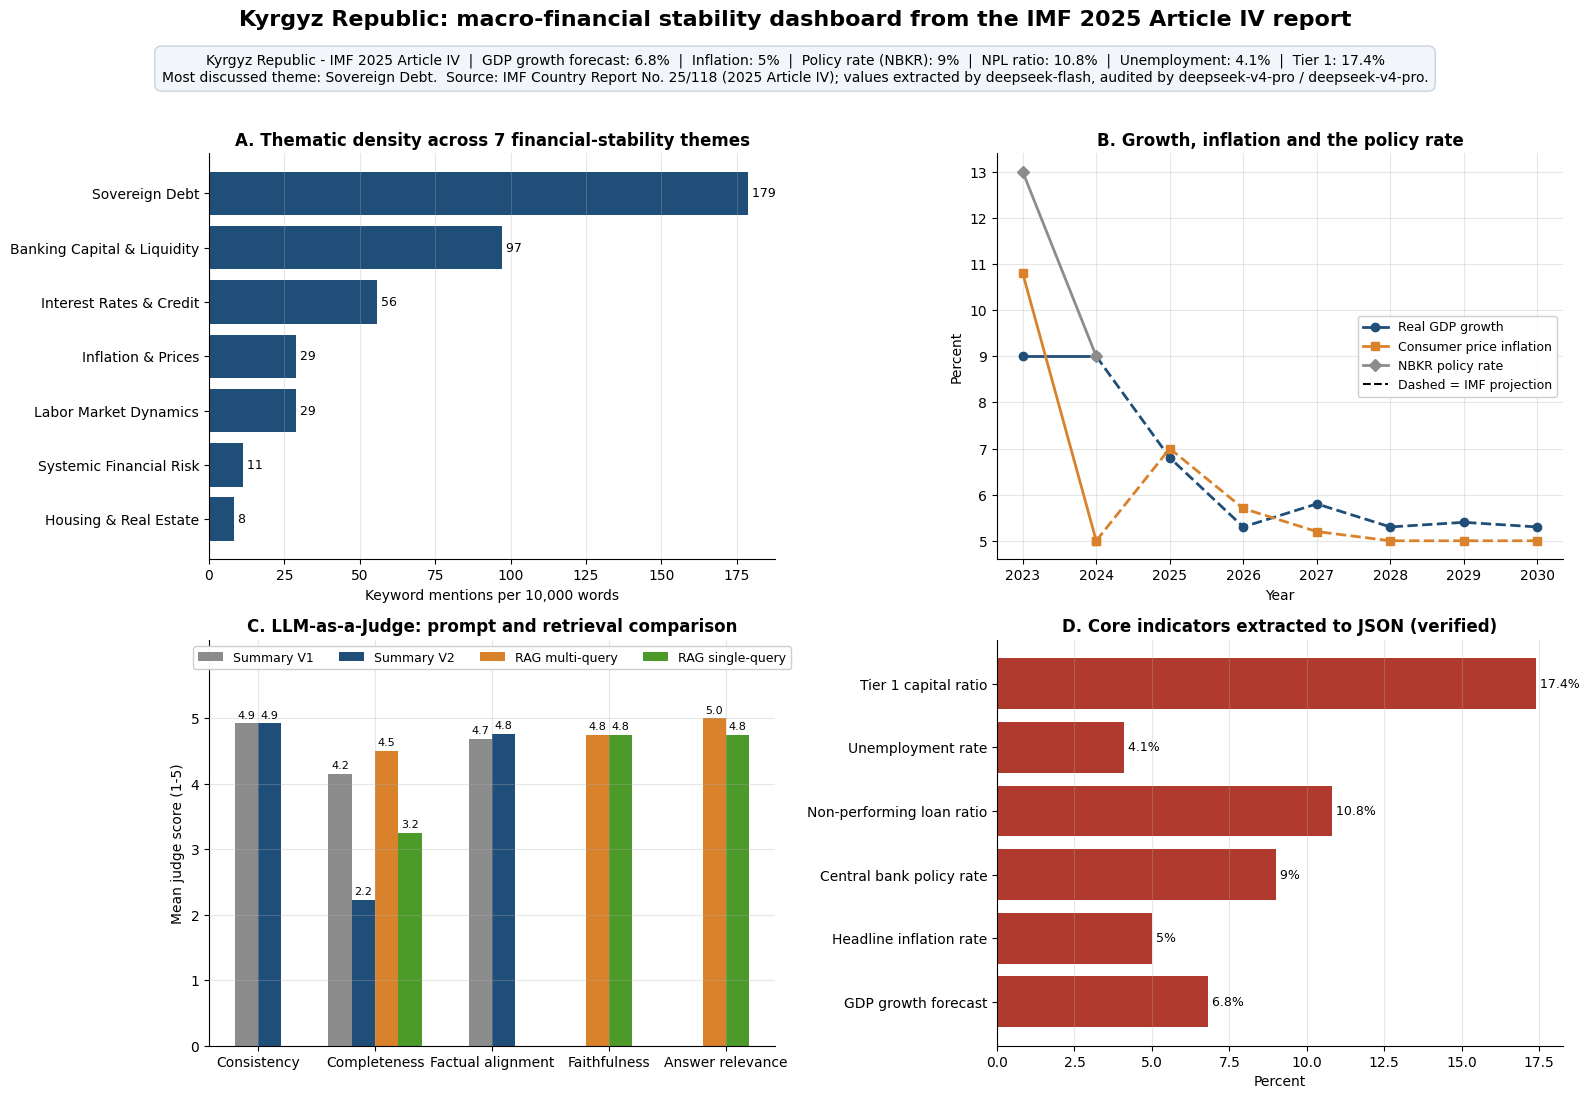

Saved outputs/dashboard.png and the four panels at 300 dpi


In [29]:
def pending(ax, title, reason=None):
    reason = reason or "Not available yet\n(an API limit stopped this step - re-run the notebook)"
    ax.set_title(title); ax.text(0.5, 0.5, reason, ha="center", va="center", transform=ax.transAxes)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
panel_themes(axes[0, 0], theme_long)
panel_trends(axes[0, 1], trends_long) if len(trends_long) else pending(axes[0, 1], "B. Growth, inflation and the policy rate")
panel_models(axes[1, 0], judge_long) if len(judge_long) else pending(axes[1, 0], "C. LLM-as-a-Judge comparison")
if len(fsi) >= 3:
    panel_credit_npl(axes[1, 1], fsi)
elif len(banking):
    panel_banking(axes[1, 1], banking, len(fsi))
elif len(indicators_long.dropna()):
    panel_indicators(axes[1, 1], indicators_long)
else:
    pending(axes[1, 1], "D. Bank asset quality")

def fmt(v, unit="%"):
    return "n/a (not reported)" if v is None else f"{v:g}{unit}"
ind = indicators or {}
top_theme = max(themes["per_10k_words"], key=themes["per_10k_words"].get)
overlay = (f"{COUNTRY} - IMF {REPORT_YEAR} Article IV  |  GDP growth forecast: {fmt(ind.get('gdp_growth_forecast_pct'))}  |  "
           f"Inflation: {fmt(ind.get('headline_inflation_rate_pct'))}  |  Policy rate ({CENTRAL_BANK}): {fmt(ind.get('central_bank_policy_rate_pct'))}  |  "
           f"NPL ratio: {fmt(ind.get('non_performing_loan_ratio'))}  |  Unemployment: {fmt(ind.get('unemployment_rate_pct'))}  |  "
           f"Tier 1: {fmt(ind.get('tier_1_capital_ratio'))}\nMost discussed theme: {top_theme}.  Source: {REPORT_ID}; values extracted by "
           f"{EXTRACTOR_MODEL}, audited by {JUDGE_MODEL} / {JUDGE_MODEL_2}.")
fig.suptitle(f"{COUNTRY}: macro-financial stability dashboard from the IMF {REPORT_YEAR} Article IV report", fontsize=16, fontweight="bold", y=0.995)
fig.text(0.5, 0.955, overlay, ha="center", va="top", fontsize=10, bbox=dict(boxstyle="round,pad=0.5", fc="#F2F5F9", ec="#C9D3DF"))
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(os.path.join(OUT_DIR, "dashboard.png"), dpi=300, bbox_inches="tight")
for (r, c), name in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ["panel_A_themes", "panel_B_trends", "panel_C_judge", "panel_D_credit_npl"]):
    extent = axes[r, c].get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), dpi=300, bbox_inches=extent.expanded(1.04, 1.06))
plt.show()
print("Saved outputs/dashboard.png and the four panels at 300 dpi")

## 7. Run summary
API calls per model (live vs. cached) and latency. Used in the report to discuss cost, quota and speed.

In [30]:
call_log = pd.DataFrame(CALL_LOG)
save_json(call_log.to_dict(orient="records"), "call_log.json")
print("Calls:", len(call_log), "| served from cache:", int(call_log["cached"].sum()) if len(call_log) else 0)
print("Output files:", sorted(os.listdir(OUT_DIR)))
cost = pd.to_numeric(call_log["cost_usd"], errors="coerce") if "cost_usd" in call_log else pd.Series(dtype=float)
if cost.notna().any():                       # OpenRouter reports cost per call; DeepSeek does not (see its usage page)
    print("Total API cost of live calls: $%.3f" % cost.sum())
call_log.groupby(["model", "cached"]).agg(calls=("tag", "count"), mean_latency_s=("latency_s", "mean")).round(2) if len(call_log) else call_log

saved outputs/call_log.json
Calls: 81 | served from cache: 80
Output files: ['call_log.json', 'chunks.json', 'closed_book_comparison.json', 'dashboard.png', 'executive_summary.json', 'indicators.json', 'indicators_detailed.json', 'indicators_long.json', 'judge_long.json', 'multi_query_rag.json', 'panel_A_themes.png', 'panel_B_trends.png', 'panel_C_judge.png', 'panel_D_credit_npl.png', 'rag_results.json', 'risk_insights.json', 'section_summaries.json', 'sections.json', 'structured_audits.json', 'summary_judge_scores.json', 'theme_long.json', 'themes.json', 'trends.json', 'trends_long.json']


calls  mean_latency_s
model           cached                       
deepseek-flash  False       1           27.25
                True       38            9.63
deepseek-v4-pro True       42           32.16